In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from forecast_utils import BASELINES, rolling_origin, summarize

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

long = pd.read_csv(PROC / "log_index_segments.csv")
long["ym"] = pd.PeriodIndex(long["ym"], freq="M")
COMS = sorted(long["commodity"].unique())

def get_series(c, seg):
    d = long[(long["commodity"] == c) & (long["segment"] == seg)].sort_values("ym")
    return pd.Series(d["log_idx"].to_numpy(), index=pd.PeriodIndex(d["ym"], freq="M"))

In [2]:
HORIZONS = [1, 3, 6, 12]
MIN_TRAIN = {"A": 24, "B": 24}     # months of data before the first forecast origin

In [3]:
parts = []
for seg in ["A", "B"]:
    for c in COMS:
        parts.append(rolling_origin(get_series(c, seg), BASELINES, HORIZONS,
                                    MIN_TRAIN[seg], commodity=c, segment=seg))
F = pd.concat(parts, ignore_index=True)
F.to_csv(PROC / "forecasts_baselines.csv", index=False)
print("Forecast rows:", len(F))

# How many forecasts does each cell of the evaluation rest on?
cnt = (F[(F["method"] == "naive") & (F["commodity"] == COMS[0])]
         .groupby(["segment", "target_period", "h"]).size().unstack())
display(cnt)

Forecast rows: 3480


h                      1   3   6   12
segment target_period                
A       Pre-COVID      17  15  12   6
B       During-COVID   13  11   8   2
        Post-COVID     37  37  37  37

In [4]:
S_com = summarize(F, ["commodity", "segment", "h", "method"])
S_com.to_csv(TAB / "08_baseline_metrics.csv", index=False)

tB = S_com[S_com["segment"] == "B"].pivot_table(index=["commodity", "h"],
                                                columns="method", values="MAE")
display(tB.loc[(slice(None), [1, 12]), :])

# Which baseline wins (lowest MAE) in each commodity-horizon cell?
for seg in ["A", "B"]:
    t = S_com[S_com["segment"] == seg].pivot_table(index=["commodity", "h"],
                                                   columns="method", values="MAE")
    t["best"] = t[["naive", "snaive", "drift"]].idxmin(axis=1)
    print(f"\nSegment {seg}: number of commodities where each baseline wins")
    display(t.groupby("h")["best"].value_counts().unstack(fill_value=0))

# MASE of the naive forecast at h=1, Segment B
display(S_com[(S_com["method"] == "naive") & (S_com["segment"] == "B") & (S_com["h"] == 1)]
        [["commodity", "MASE"]])

# Same table broken down by target period (use with care, see the notes below)
S_per = summarize(F, ["commodity", "segment", "target_period", "h", "method"])
S_per.to_csv(TAB / "08_baseline_metrics_by_period.csv", index=False)

method                            drift  naive  snaive
commodity                     h                       
Meat (beef, chops with bones) 1    0.55   0.41    5.61
                              12   6.46   3.91    3.91
Meat (chicken, whole)         1    1.39   1.20    6.18
                              12   7.30   4.11    4.11
Meat (pork)                   1    1.31   1.07    5.42
                              12   9.54   5.38    5.38
Onions (red)                  1   10.98  10.91   34.97
                              12  43.34  34.16   34.16
Rice (regular, milled)        1    1.92   1.86   12.23
                              12  15.68  14.59   14.59


Segment A: number of commodities where each baseline wins


best,drift,naive,snaive
h,,,
1,2,3,0
3,1,4,0
6,1,3,1
12,3,2,0



Segment B: number of commodities where each baseline wins


best,naive
h,
1,5
3,5
6,5
12,5


,commodity,MASE
13,"Meat (beef, chops with bones)",0.50
37,"Meat (chicken, whole)",0.67
61,Meat (pork),0.67
85,Onions (red),0.91
109,"Rice (regular, milled)",1.94


Seasonal naive equals naive at h=12: True


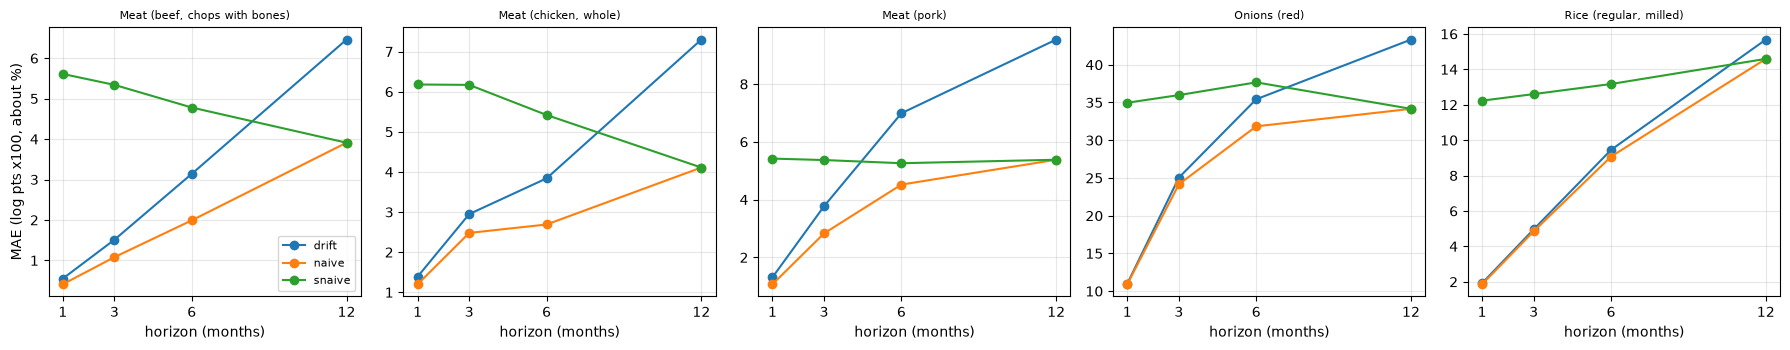

In [5]:
chk = (F[(F["h"] == 12) & (F["method"] == "naive")]["y_pred"].to_numpy()
       == F[(F["h"] == 12) & (F["method"] == "snaive")]["y_pred"].to_numpy()).all()
print("Seasonal naive equals naive at h=12:", chk)

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharex=True)
for ax, c in zip(axes, COMS):
    d = S_com[(S_com["commodity"] == c) & (S_com["segment"] == "B")]
    for m, g in d.groupby("method"):
        ax.plot(g["h"], g["MAE"], marker="o", label=m)
    ax.set_title(c, fontsize=8); ax.set_xlabel("horizon (months)"); ax.set_xticks(HORIZONS)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MAE (log pts x100, about %)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "08_baseline_mae_by_horizon.png", dpi=150)
plt.show()